# VigiLense: Fire & Smoke detection (D-Fire) with YOLO26

**Files needed in Google Drive, folder `My Drive/vigilense/datasets/`:**
1. `D-Fire-images.zip`: the big download called **"D-Fire dataset (only images and labels)"** from the D-Fire GitHub page.
2. `dfire_train.txt` and `dfire_test.txt`: the official split lists, from the small download called "Training, validation and test sets". (Ignore `video_*.txt` and the `5-fold` folder.)

Then in Colab: **Runtime > Change runtime type > T4 GPU**.

Run the cells top to bottom. Start with `QUICK_TEST = True` (a few minutes) to prove everything works, then set it to `False` for the real run.

Cite the D-Fire paper in your report (Venancio et al., Neural Computing and Applications, 2022).

In [ ]:
# 1) GPU check + install + connect Google Drive
!nvidia-smi
!pip install -U -q ultralytics

from google.colab import drive
drive.mount('/content/drive')

Sat Oct 17 22:03:42 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# 2) Paths and settings
from pathlib import Path

DRIVE_ROOT = "/content/drive/MyDrive/vigilense"
DS         = f"{DRIVE_ROOT}/datasets"
ZIP_PATH   = f"{DS}/D-Fire-images.zip"
RAW_DIR    = Path("/content/D-Fire")        # extracted dataset (local disk = fast)
CFG_DIR    = Path("/content/dfire_cfg")     # split lists + data.yaml

QUICK_TEST = False    # True = 3-epoch test on 10% of data. Set False for real training.
EPOCHS     = 3 if QUICK_TEST else 50
RUN_NAME   = "fire_smoke_quick" if QUICK_TEST else "fire_smoke_v1"

for f in ["D-Fire-images.zip", "dfire_train1.txt", "dfire_valid1.txt", "dfire_test.txt"]:
    assert Path(f"{DS}/{f}").exists(), f"Missing in Drive: {f}"
print("All files found. QUICK_TEST =", QUICK_TEST)

All files found. QUICK_TEST = False


In [ ]:
# 3) Copy the zip to local disk and unzip
import os, shutil, subprocess

LOCAL_ZIP = "/content/D-Fire-images.zip"

if (RAW_DIR / "train" / "images").exists() and (RAW_DIR / "test" / "images").exists():
    print("Dataset already extracted, skipping.")
else:
    if not os.path.exists(LOCAL_ZIP) or os.path.getsize(LOCAL_ZIP) < 2_500_000_000:
        print("Copying zip from Drive...")
        shutil.copy(ZIP_PATH, LOCAL_ZIP)
    print("Unzipping...")
    RAW_DIR.mkdir(parents=True, exist_ok=True)
    r = subprocess.run(["unzip", "-o", "-q", LOCAL_ZIP, "-d", str(RAW_DIR)], capture_output=True, text=True)
    print(r.stderr[-500:])

n_files = sum(1 for p in RAW_DIR.rglob("*") if p.is_file())
print("Files in dataset:", n_files)       # expect ~43,054
assert n_files > 40000, "Extraction looks incomplete."

Copying zip from Drive...
Unzipping...

Files in dataset: 43054


In [ ]:
# 4) Build train / val / test folders from the official split lists
import yaml

CFG_DIR.mkdir(parents=True, exist_ok=True)

def build(list_file, subdir, out_name):
    paths, missing = [], 0
    for line in Path(f"{DS}/{list_file}").read_text().splitlines():
        name = Path(line.strip().replace("\\", "/")).name
        if not name:
            continue
        p = RAW_DIR / subdir / "images" / name
        if p.exists():
            paths.append(str(p))
        else:
            missing += 1
    (CFG_DIR / out_name).write_text("\n".join(paths))
    print(f"{out_name:10s}: {len(paths)} images | missing: {missing}")
    return paths

train_paths = build("dfire_train1.txt", "train", "train.txt")
val_paths   = build("dfire_valid1.txt", "train", "val.txt")
test_paths  = build("dfire_test.txt",   "test",  "test.txt")
print("train/val overlap (must be 0):", len(set(train_paths) & set(val_paths)))

DATA_YAML = CFG_DIR / "data.yaml"
DATA_YAML.write_text(yaml.safe_dump({
    "train": str(CFG_DIR / "train.txt"),
    "val":   str(CFG_DIR / "val.txt"),
    "test":  str(CFG_DIR / "test.txt"),
    "names": {0: "smoke", 1: "fire"},
}, sort_keys=False))
print(DATA_YAML.read_text())

train.txt : 13776 images | missing: 0
val.txt   : 3445 images | missing: 0
test.txt  : 4306 images | missing: 0
train/val overlap (must be 0): 0
train: /content/dfire_cfg/train.txt
val: /content/dfire_cfg/val.txt
test: /content/dfire_cfg/test.txt
names:
  0: smoke
  1: fire



In [ ]:
# 5) Sanity check: counts, class ids, and empty labels (= negative images)
from collections import Counter

def label_stats(paths):
    classes, empty = Counter(), 0
    for p in paths:
        lp = Path(p.replace("/images/", "/labels/")).with_suffix(".txt")
        lines = [l for l in lp.read_text().splitlines() if l.strip()] if lp.exists() else []
        if not lines:
            empty += 1
        classes.update(l.split()[0] for l in lines)
    return dict(classes), empty

for name, ps in [("train", train_paths), ("val", val_paths), ("test", test_paths)]:
    cls, empty = label_stats(ps)
    print(f"{name:5s}: {len(ps)} images | boxes per class {cls} | background images: {empty}")

print("\nExpected: only class ids '0' (smoke) and '1' (fire).")

train: 13776 images | boxes per class {'1': 9659, '0': 7660} | background images: 6223
val  : 3445 images | boxes per class {'0': 1890, '1': 2155} | background images: 1610
test : 4306 images | boxes per class {'0': 2315, '1': 2878} | background images: 2005

Expected: only class ids '0' (smoke) and '1' (fire).


In [ ]:
# 6) Train (results and checkpoints are saved straight to Google Drive)
from ultralytics import YOLO

model = YOLO("yolo26n.pt")      # if this fails to download, use "yolo11n.pt"
model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=640,
    batch=16,
    patience=15,
    fraction=0.1 if QUICK_TEST else 1.0,
    project=f"{DRIVE_ROOT}/runs",
    name=RUN_NAME,
    exist_ok=True,
    workers=2,
    plots=True,
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.181 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dfire_cfg/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, fr

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7c08dee72f20>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

In [10]:
# 7) Evaluate the best model on the TEST split
BEST = f"{DRIVE_ROOT}/runs/{RUN_NAME}/weights/best.pt"
metrics = YOLO(BEST).val(data=str(DATA_YAML), split="test", imgsz=640)
print(f"mAP50: {metrics.box.map50:.3f} | mAP50-95: {metrics.box.map:.3f}")
print(f"Precision: {metrics.box.mp:.3f} | Recall: {metrics.box.mr:.3f}")

Ultralytics 8.4.181 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2123.0±1217.7 MB/s, size: 102.0 KB)
val: Scanning /content/D-Fire/test/labels.cache... 4306 images, 2005 backgrounds, 4 corrupt: 100% ━━━━━━━━━━━━ 4306/4306 1.4Git/s 0.0s
val: /content/D-Fire/test/images/WEB10769.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [1.0296875]
val: /content/D-Fire/test/images/WEB10775.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [1.015625]
val: /content/D-Fire/test/images/WEB11243.jpg: corrupt JPEG restored and saved
val: /content/D-Fire/test/images/WEB11244.jpg: corrupt JPEG restored and saved
val: /content/D-Fire/test/images/WEB11245.jpg: corrupt JPEG restored and saved
val: /content/D-Fire/test/images/WEB11313.jpg: corrupt JPEG restored and saved
val: /content/D-Fire/test/image

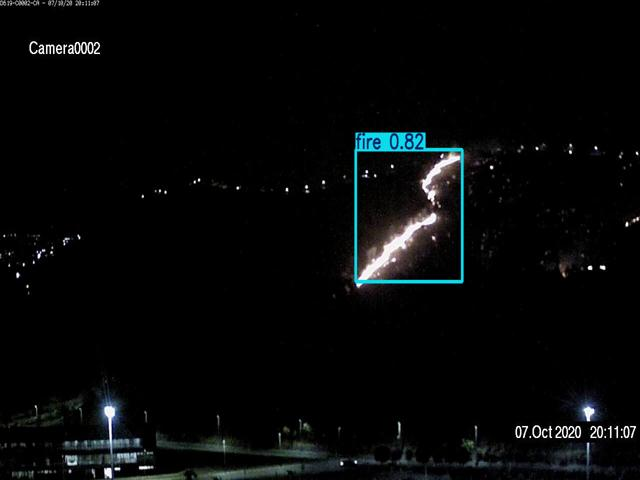

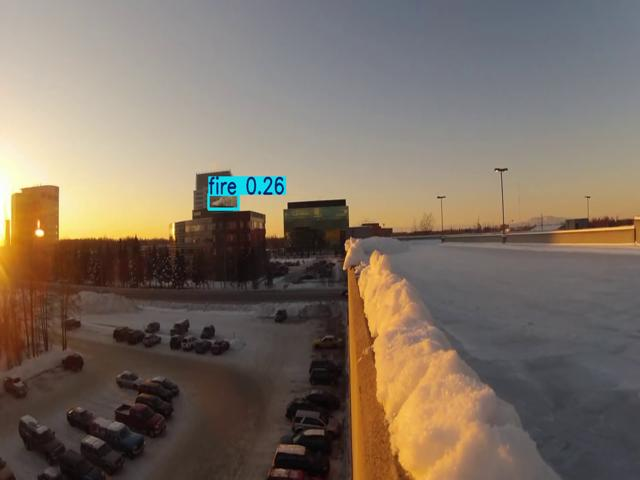

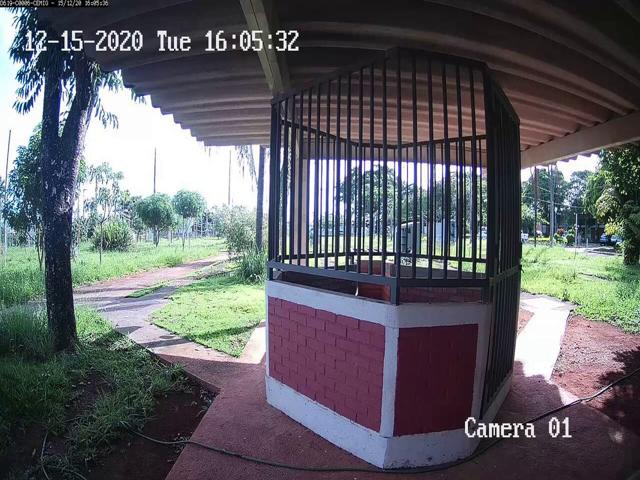

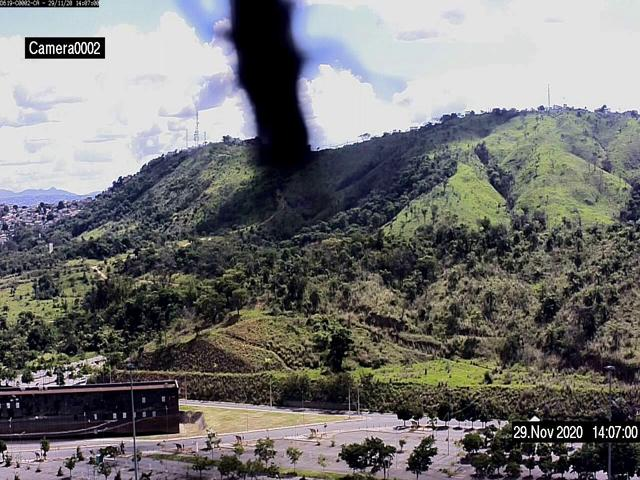

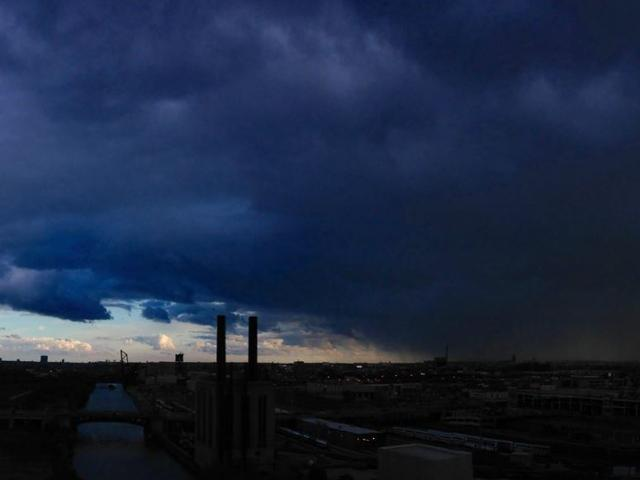

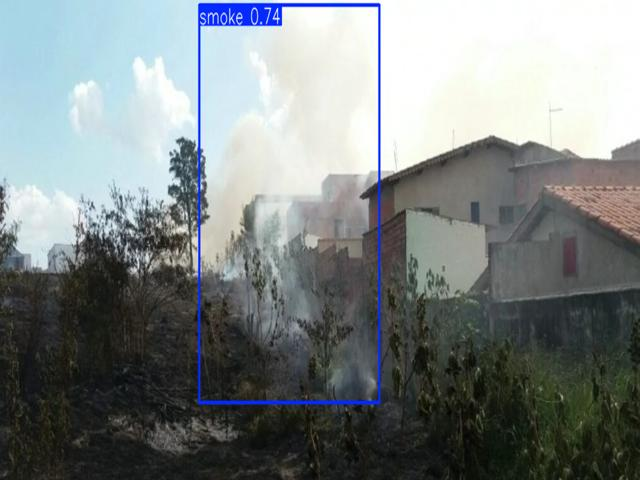

In [11]:
# 8) Look at predictions on random test images
import random
from PIL import Image
from IPython.display import display

best_model = YOLO(BEST)
for p in random.sample(test_paths, 6):
    r = best_model.predict(p, conf=0.25, verbose=False)[0]
    display(Image.fromarray(r.plot()[..., ::-1]).resize((640, 480)))

## If Colab disconnects during a long run
Re-run cells 1 and 2 (and 3 to 4 if the local dataset is gone), then run the cell below to continue from the last checkpoint. Set `QUICK_TEST = False` first.

In [ ]:
# Resume an interrupted training run
last = f"{DRIVE_ROOT}/runs/{RUN_NAME}/weights/last.pt"
YOLO(last).train(resume=True)

## After training
`best.pt` is in Google Drive at `vigilense/runs/<run name>/weights/best.pt`. Download it, put it in your project's `weights/` folder, and test on your laptop:

`yolo predict model=weights\best.pt source="data\test.mp4" show=True`